In [ ]:
import os
from google.colab import drive

# 1. Mount Google Drive using the standard path
mountpoint = "/content/drive"
drive.mount(mountpoint, force_remount=True)

# 2. Define your folder and file paths correctly
# CHANGED: extraction_dir is now a folder, not a .zip filename
extraction_dir = "/content/drive/MyDrive/penguin"
zip_file_path = "/content/drive/MyDrive/penguin.zip"

# 3. Create the extraction folder if it doesn't exist
if not os.path.exists(extraction_dir):
    os.makedirs(extraction_dir)
    print(f"Created directory: {extraction_dir}")

# 4. Unzip the file into the folder
!unzip "{zip_file_path}" -d "{extraction_dir}"

# 5. Check user identity
!whoami

Mounted at /content/drive
Created directory: /content/drive/MyDrive/penguin
Archive:  /content/drive/MyDrive/penguin.zip
  inflating: /content/drive/MyDrive/penguin/penguins_size.csv  
root



--- Classification Report ---
              precision    recall  f1-score   support

      Adelie       0.96      0.98      0.97        46
   Chinstrap       1.00      0.95      0.98        21
      Gentoo       0.97      0.97      0.97        37

    accuracy                           0.97       104
   macro avg       0.98      0.97      0.97       104
weighted avg       0.97      0.97      0.97       104


--- Feature Importance Ranks ---
culmen_length_mm     0.398453
flipper_length_mm    0.292451
culmen_depth_mm      0.247176
body_mass_g          0.061921
dtype: float64


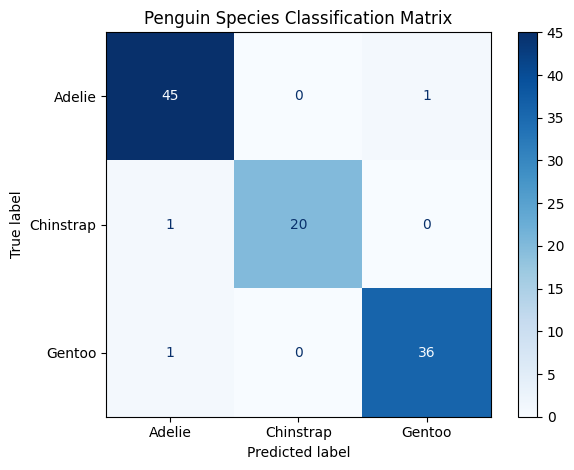

Raw Predictions from List: ['Adelie' 'Gentoo' 'Adelie']
Predictions from DataFrame: ['Adelie' 'Gentoo' 'Adelie']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("/content/drive/MyDrive/penguin/penguins_size.csv")


X = df[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = df['species']


imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)


valid_indices = y.dropna().index
X_imputed = X_imputed.loc[valid_indices]
y = y.loc[valid_indices]

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.3, random_state=42, stratify=y
)


model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Model Evaluation
y_pred = model.predict(X_test)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# 6. Feature Importance Rank
importances = pd.Series(model.feature_importances_, index=X_imputed.columns).sort_values(ascending=False)
print("\n--- Feature Importance Ranks ---")
print(importances)

# 7. Generate a Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues')
plt.title('Penguin Species Classification Matrix')
plt.tight_layout()
plt.show()

# 8. PREDICT NEW UNSEEN PENGUIN DATA
new_penguins_list = [
    [45.0, 18.5, 200.0, 4100.0],  # New Penguin 1
    [50.5, 15.2, 216.0, 5550.0],  # New Penguin 2
    [37.8, 17.1, 186.0, 3300.0]   # New Penguin 3
]

predictions_raw = model.predict(new_penguins_list)

new_penguins_df = pd.DataFrame(new_penguins_list, columns=X_imputed.columns)
predictions_df = model.predict(new_penguins_df)

print(f"Raw Predictions from List: {predictions_raw}")
print(f"Predictions from DataFrame: {predictions_df}")
